<a href="https://colab.research.google.com/github/rijoysebastian/OIBSIP/blob/main/Remote_internship.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
from sklearn.datasets import load_iris

Load the Iris dataset

In [3]:
iris = load_iris()

In [4]:
data = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)


In [5]:
data

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
...,...,...,...,...
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3


In [6]:
data['species'] = iris.target
data.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [7]:
data['species'] = data['species'].map({
    0:'setosa',
    1:'versicolor',
    2:'virginica'
})

In [8]:
data['species'].value_counts()

,count
species,
setosa,50
versicolor,50
virginica,50


Exploratory Data Analysis (EDA)

In [9]:
data.shape

(150, 5)

Check column information

In [10]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


Finding duplicates

In [11]:
data.duplicated().sum()

np.int64(1)

Finding missing values

In [12]:
data.isna().sum()

,0
sepal length (cm),0
sepal width (cm),0
petal length (cm),0
petal width (cm),0
species,0


Statistical description

In [13]:
data.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


  VISUALIZATION

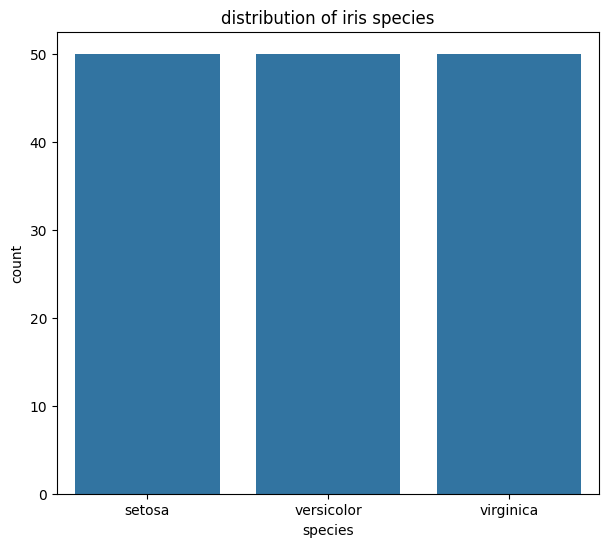

In [14]:
plt.figure(figsize=(7,6))
sns.countplot(data=data,x='species')
plt.title('distribution of iris species')
plt.xlabel('species')
plt.ylabel('count')
plt.show()

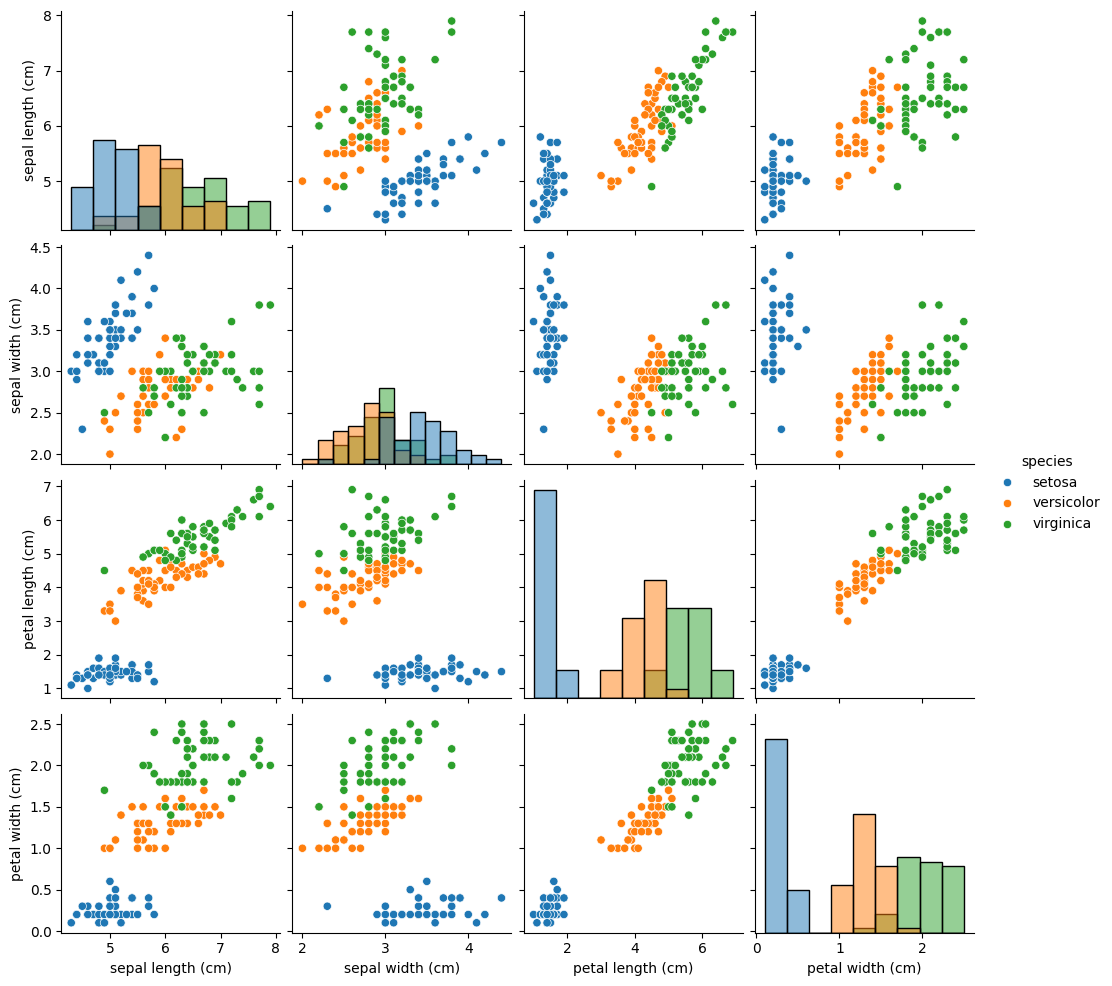

In [15]:
sns.pairplot(data,hue='species',
             diag_kind='hist')
plt.show()

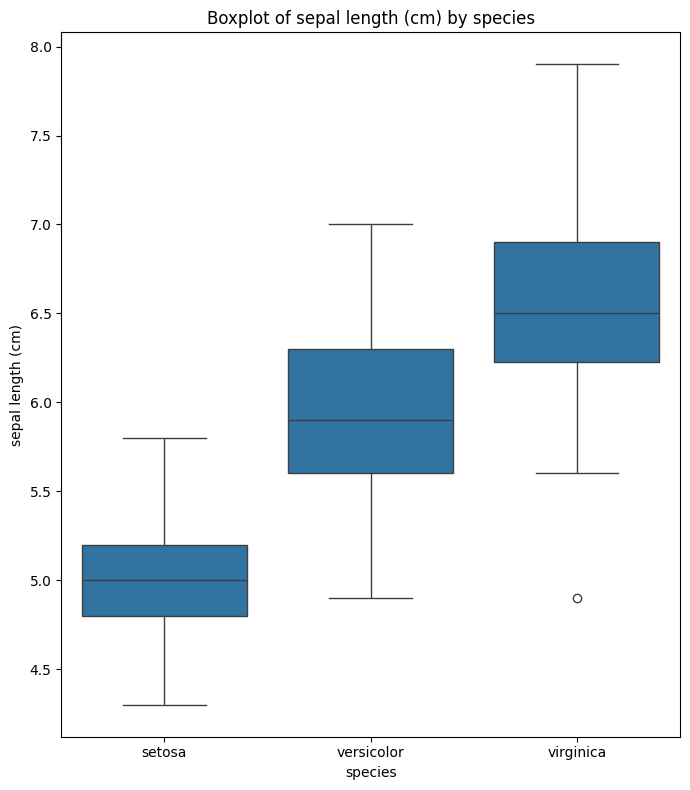

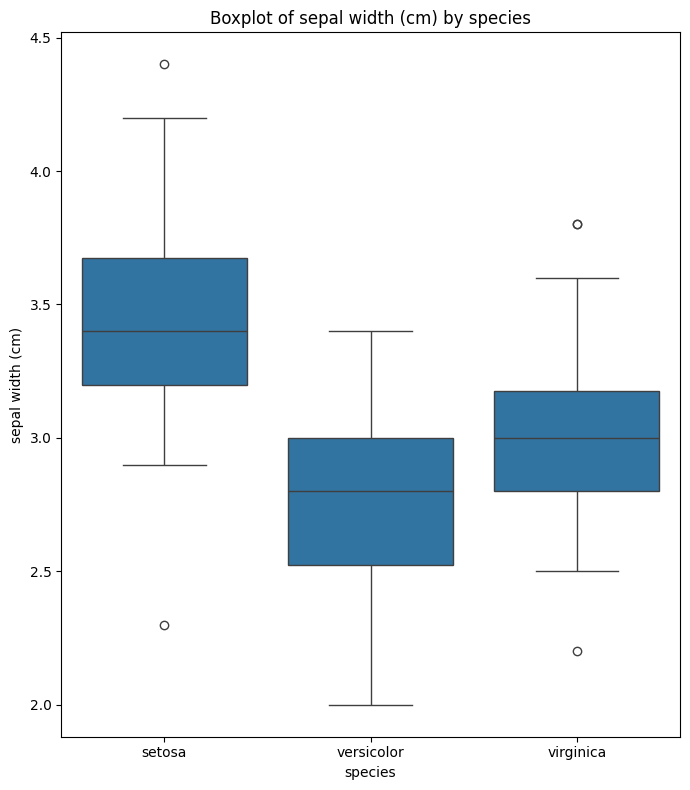

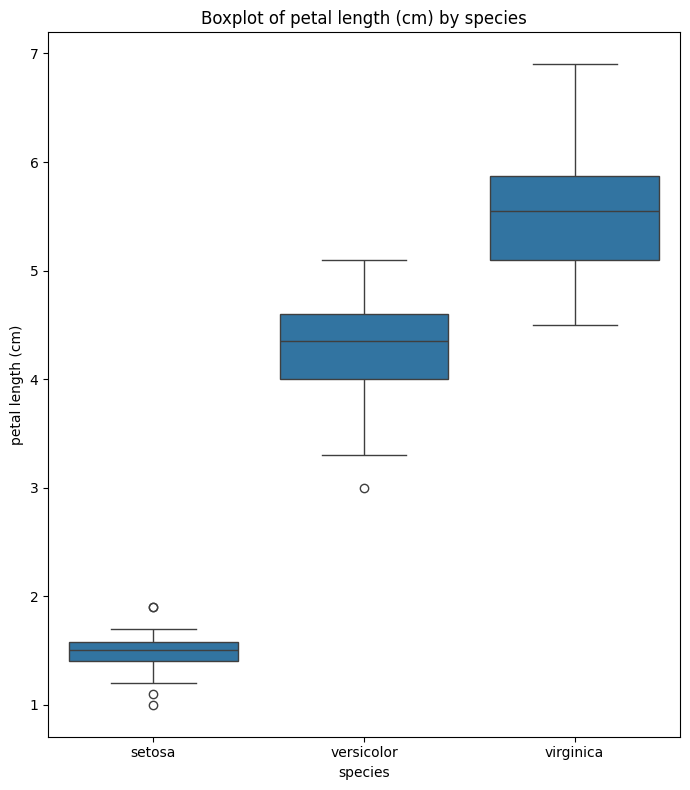

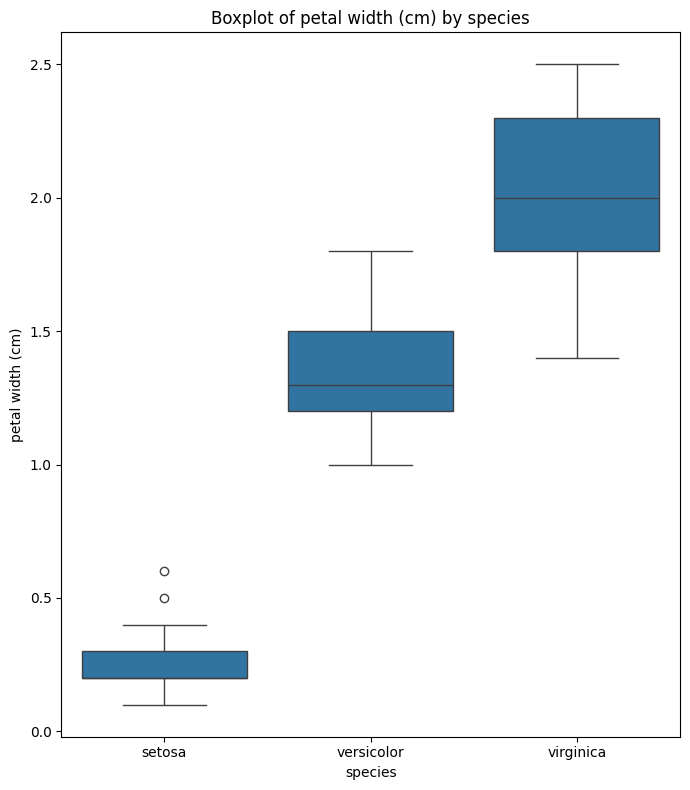

In [16]:
columns = [
    'sepal length (cm)',
    'sepal width (cm)',
    'petal length (cm)',
    'petal width (cm)',
]
for i in columns:
  plt.figure(figsize=(7,8))
  sns.boxplot(data=data,
              x='species',
              y=i)
  plt.title(f'Boxplot of {i} by species')
  plt.tight_layout()
  plt.show()

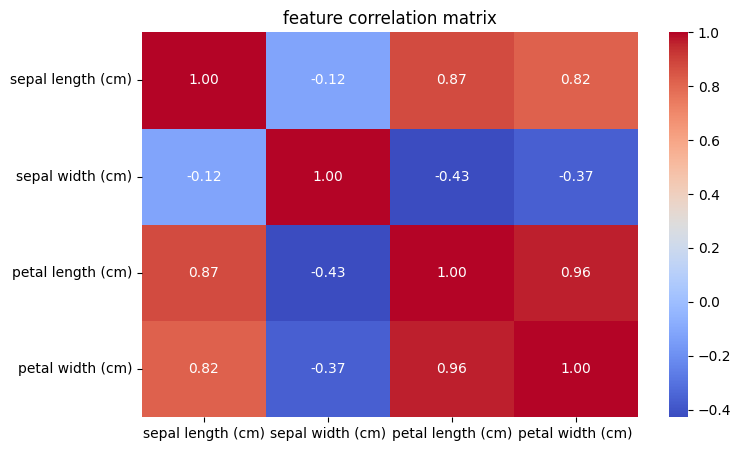

In [17]:
correlation_matrix = data.select_dtypes(include=[float, int]).corr()
plt.figure(figsize=(8,5))
sns.heatmap(correlation_matrix,annot=True, cmap='coolwarm', fmt='.2f')
plt.title('feature correlation matrix')
plt.show()

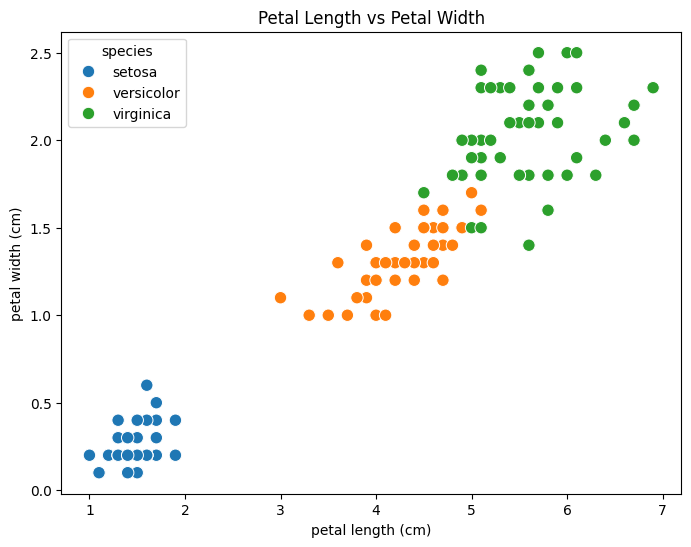

In [18]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=data,
    x='petal length (cm)',
    y='petal width (cm)',
    hue='species',
    s=80
)

plt.title('Petal Length vs Petal Width')
plt.show()

In [19]:
from sklearn.model_selection import train_test_split

Split the dataset into training and testing

In [20]:
x = data.drop('species' , axis=1)
y = data['species']
x_train,x_test,y_train,y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,)
print("train data:",x_train.shape)
print("test data:",x_test.shape)



train data: (120, 4)
test data: (30, 4)


Feature Scaling

In [22]:
from sklearn.preprocessing import StandardScaler


In [24]:
scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)

x_test_scaled = scaler.transform(x_test)

In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

In [28]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

Logistic Regression
Model Evaluation(confusion matrix,accuracy,classification report)

In [34]:
lr = LogisticRegression(max_iter=200)

lr.fit(x_train_scaled, y_train)

lr_pred = lr.predict(x_test_scaled)

print("Logistic Regression Accuracy:",
      accuracy_score(y_test, lr_pred),
      confusion_matrix(y_test, lr_pred),
      classification_report(y_test, lr_pred))

Logistic Regression Accuracy: 1.0 [[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



K-Nearest Neighbours (KNN)
Model Evaluation(confusion matrix,accuracy,classification report)

In [35]:
knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(x_train_scaled, y_train)

knn_pred = knn.predict(x_test_scaled)

print("KNN Accuracy:",
       accuracy_score(y_test, knn_pred),
      confusion_matrix(y_test, knn_pred),
      classification_report(y_test, knn_pred))

KNN Accuracy: 1.0 [[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



Decision Tree
Model Evaluation(confusion matrix,accuracy,classification report)

In [36]:
dt = DecisionTreeClassifier(random_state=42)

dt.fit(x_train, y_train)

dt_pred = dt.predict(x_test)

print("Decision Tree Accuracy:",
       accuracy_score(y_test, dt_pred),
      confusion_matrix(y_test, dt_pred),
      classification_report(y_test, dt_pred))

Decision Tree Accuracy: 1.0 [[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



Random Forest
Model Evaluation(confusion matrix,accuracy,classification report)

In [37]:
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(x_train, y_train)

rf_pred = rf.predict(x_test)

print("Random Forest Accuracy:",
       accuracy_score(y_test, rf_pred),
      confusion_matrix(y_test, rf_pred),
      classification_report(y_test, rf_pred))

Random Forest Accuracy: 1.0 [[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



Best model preformances

In [44]:
models_performance = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'K-Nearest Neighbors',
        'Decision Tree',
        'Random Forest',
    ],
    'Accuracy': [
        accuracy_score(y_test, lr_pred),
        accuracy_score(y_test, knn_pred),
        accuracy_score(y_test, dt_pred),
        accuracy_score(y_test, rf_pred),
    ],
})

models_performance = models_performance.sort_values(
    by='Accuracy', ascending=False
).reset_index(drop=True)


best_model_name = models_performance.iloc[0]['Model']
best_accuracy = models_performance.iloc[0]['Accuracy'] * 100

print('Model Performance Summary:')
display(models_performance)

print(f'\nBest Performing Model: {best_model_name}')
print(f'Best Accuracy: {best_accuracy}%')

Model Performance Summary:


,Model,Accuracy
0,Logistic Regression,1.0
1,K-Nearest Neighbors,1.0
2,Decision Tree,1.0
3,Random Forest,1.0



Best Performing Model: Logistic Regression
Best Accuracy: 100.0%


Best Model Justification:

The selected model achieved the highest accuracy among the tested classifiers. It also demonstrated good precision, recall, and F1-score, with fewer classification errors. Therefore, it was chosen as the best-performing model for Iris flower classification.